# BQ2 Track B: July–August screening across 20 zones

**2018 reference versus 2019 evaluation**, Floors 3–7, zones 1, 2, 4 and 5. This expands the reviewed F3-Z1 example, preserving the prior audit and first-pass output folders.

## Findings to review

| Inspection lead | With existing fills | Without filled/replaced readings | Interpretation |
|---|---:|---:|---|
| **F3-Z4: energy and controls** | +13.3% energy, 22 supported days | +15.2%, 10 days | Stronger reference validation; inspect operating conditions before attributing an efficiency change |
| **F5-Z4: energy change** | +36.7%, 23 days | +36.7%, 23 days | Large consistent departure, but weather reference fails the simple validation benchmark; mean-only sensitivity is +33.0% |
| **F7-Z2: moisture conditions** | +1.15 g/kg, 33 days | +1.14 g/kg, 29 days | Recorded absolute moisture rises; the observed-only reference slightly misses the validation benchmark. Mean-only sensitivity agrees |

**Verify the inputs separately:** F4-Z1 and F7-Z1 have near-all-zero AC channels; F5-Z1 has suspect environmental readings. These warrant configuration/sensor checks, not a fault diagnosis. F5-Z1 energy is assessed separately.

No zone supports a fair adjusted cooling-rate comparison under this pass's coverage and common-support rules. Absence of a reported signal does not establish healthy equipment. The results below are exploratory inspection leads, not confirmed degradation, mould or a completed joint risk matrix.


## Methods and decision rules

- Scope remains **July–August 2018 and 2019**. Raw/cleaned minute sources are checked before modelling; no cleaning or weather cache is regenerated. Explicit source date formats follow the upstream cleaning notebook.
- **With fills** uses existing cleaned values. **Without fills** retains only present source values unchanged by cleaning. No missing-day scaling, new interpolation or removal of zero-valued AC channels is performed. Both versions share the same zone-specific AC threshold, frozen from raw-observed 2018.
- Feature definitions match the first F3-Z1 pass: complete 1,440-minute AC-plus-plug days for energy; scheduled continuous 60-minute start-up windows for cooling; complete sensor/plug hours after at least 120 continuous AC-on minutes for moisture. AC totals require every configured meter. Plug load and `working day` are activity proxies.
- Quality checks cover timestamp keys/grids, channel validity, full-period and requested-window coverage, exact sensor plateaus, zero meters, fills/replacements, upstream quality logs and independent hourly reconciliation. F5-Z1 environmental outputs and F4-Z1/F7-Z1 meter-dependent outputs are held for verification. Zero power does not establish a failed AC.
- All coefficients and energy-model selection use **2018 only**. Temperature-plus-plug and enthalpy-plus-plug compete in expanding 2018 validation. Mean/activity references are benchmarks. Cooling uses initial temperature, outdoor temperature and session; moisture uses outdoor humidity ratio, outdoor temperature, plug activity and session. Constant 2018 predictors are omitted, while session support is still enforced.
- Each metric/version needs **20 reference days over at least four calendar weeks** to fit. A reported departure needs at least **10 supported evaluation days across four weeks**, with predictors inside the 2018 convex hull, separately by session for environmental comparisons. These are conservative project rules, not scientific fault thresholds.
- Days receive equal total weight. Nominal conditional 95% intervals use **2,000 calendar-week bootstrap replicates**, refitting the reference. Model choice and supported cohort stay fixed. There is no adjustment for screening multiple zones; intervals are not simultaneous confidence guarantees.
- A stronger inspection lead requires the reference's temporal validation MAE to beat a mean-only reference and a consistent adverse direction in both input versions. A separate **validate-reference queue** retains large/descriptive leads when both versions and a mean-only sensitivity agree, while explicitly retaining the weak-model limitation. Mean-only sensitivity uses the exact same supported evaluation rows and is not weather-adjusted.
- No numeric fault score, RUL estimate, mould threshold or handover-schema field is invented. Energy departures alone do not measure cooling efficiency; indoor humidity ratio is not coil moisture removal. The two input versions share observations, so agreement is a sensitivity check, not independent replication.

Clock convention, calibration, occupancy, maintenance, setpoints, airflow and surface conditions remain unverified. The 2018 reference is not known to be fault-free. Peer zones differ in meter configuration and unknown loads; cross-zone percentages are screening context rather than a controlled peer experiment.


In [1]:
from pathlib import Path
import hashlib
import json
import sys
import importlib.metadata as metadata
import numpy as np
import pandas as pd
from IPython.display import display, Image

RUN_CHECKS = False
%run -i ./bq2_utils.ipynb

import bq2_zone_screen as screen
import f3z1_first_pass as first_pass
repo_root = Path.cwd().parent
sys.path.insert(0, str(repo_root / "baseline"))
from humidity_risk_baseline import load_bangkok_era5_weather
output_dir = Path("outputs/bq2-zone-screen")
output_dir.mkdir(parents=True, exist_ok=True)
weather = load_bangkok_era5_weather(repo_root / "baseline/data/bangkok_era5_hourly_2018-2019.csv")
helpers = {name: globals()[name] for name in ["add_outdoor_psychrometrics", "humidity_ratio_gkg", "ac_on_threshold"]}
pd.set_option("display.max_columns", 14)


## 1. Audit sources before fitting

The raw Floor 6 tail contains one malformed row with no measurements. It is logged and excluded only from the local reader; absent trailing minutes remain missing. Floor 7's day-first source dates are parsed explicitly. All valid timestamps must be unique, ordered and on the minute grid.


In [2]:
evidence = screen.audit_and_features(repo_root, weather, helpers, output_dir)
quality = evidence["zone_quality"]
display(quality[["zone_id", "ac_meters", "full_clean_joint_coverage_pct",
                 "with_fills_2018_joint_coverage_pct", "with_fills_2019_joint_coverage_pct",
                 "suspect_sensor", "meter_mapping_review"]].round(2))
display(evidence["timestamp_audit"].query("invalid_timestamps > 0"))
assert evidence["channel_quality"].quality_log_missing_agrees.all()
assert evidence["hourly_reconciliation"][["availability_mismatches", "value_mismatches"]].sum().sum() == 0
print("All 95 relevant channel missingness records and 80 hourly comparisons reconcile.")
print("Longest requested-window raw plateaus:")
display(evidence["sensor_checks"].groupby("stream").raw_scope_max_constant_minutes.max())


F3-Z1: quality checked; sensor_review=False, meter_review=False


F3-Z2: quality checked; sensor_review=False, meter_review=False


F3-Z4: quality checked; sensor_review=False, meter_review=False


F3-Z5: quality checked; sensor_review=False, meter_review=False


F4-Z1: quality checked; sensor_review=False, meter_review=True


...

F7-Z5: quality checked; sensor_review=False, meter_review=False


,zone_id,ac_meters,full_clean_joint_coverage_pct,with_fills_2018_joint_coverage_pct,with_fills_2019_joint_coverage_pct,suspect_sensor,meter_mapping_review
0,F3-Z1,4,61.92,99.20,98.66,False,False
1,F3-Z2,1,64.88,99.07,98.92,False,False
2,F3-Z4,1,64.84,97.49,98.59,False,False
3,F3-Z5,1,54.80,80.97,96.78,False,False
4,F4-Z1,4,52.03,98.72,98.80,False,True
5,F4-Z2,1,65.66,98.31,98.67,False,False
6,F4-Z4,1,55.29,92.25,77.95,False,False
7,F4-Z5,1,66.20,90.59,98.46,False,False
8,F5-Z1,4,55.02,98.83,62.74,True,False
9,F5-Z2,1,51.50,99.11,30.36,False,False


,source,rows,invalid_timestamps,date_format,invalid_rows_with_measurements,duplicate_timestamps,sorted,first,last,off_minute_grid
13,data/2019Floor6.csv,424169,1,%Y-%m-%d %H:%M:%S,0,0,True,2019-01-01 00:00:00,2019-10-22 13:27:00,0


All 95 relevant channel missingness records and 80 hourly comparisons reconcile.
Longest requested-window raw plateaus:


stream
RH             43
paired         34
temperature    71
Name: raw_scope_max_constant_minutes, dtype: int64

**Quality implications:** F4-Z1 AC1 and AC3, and F7-Z1 AC1, are near-all-zero over the requested windows. Keep these channels visible and verify whether they are unused, unmapped or faulty before interpreting zone performance. F5-Z1's cold sensor may have unusual placement or calibration; no placement claim is verified. F5-Z2 has particularly poor 2019 environmental availability. Full-period coverage remains limited by long outages, even where July–August is usable. Raw sensor plateaus do not explain the ordinary zones' results, but calibration/drift remains unverified.


In [3]:
# A regression check for the generalised one/four-meter feature builder.
for name in ["daily_features", "event_features", "steady_on_features"]:
    expanded = evidence[name].query("zone_id == 'F3-Z1'").drop(columns=["zone_id", "floor", "zone"])
    previous = pd.read_csv(Path("outputs/f3z1-first-pass") / f"{name}.csv")
    for column in ["time", "date"]:
        if column in previous: previous[column] = pd.to_datetime(previous[column])
    expanded = expanded.sort_values(["variant", "time"]).reset_index(drop=True)
    previous = previous.sort_values(["variant", "time"]).reset_index(drop=True)
    pd.testing.assert_frame_equal(expanded, previous, check_dtype=False, rtol=1e-9, atol=1e-9)
print("F3-Z1 features reproduce the reviewed first pass without changing its saved evidence.")


F3-Z1 features reproduce the reviewed first pass without changing its saved evidence.


## 2. Fit only the comparisons supported by the quality pass

Failure or an unavailable metric stays in the results with its reason. A zone's energy can be usable even when environmental readings are not. An energy reference that does not improve the simple benchmark is retained as descriptive evidence and does not enter the stronger inspection tier.


In [4]:
result = screen.run_screen(evidence, output_dir, repetitions=2000)
summary = result["model_summary"]
display(summary.groupby(["analysis", "variant"]).agg(
    fitted=("reference_cv_MAE", "count"), supported=("reportable", "sum"),
    passes_reference_validation=("lead_eligible", "sum")))
cv = result["cross_validation"]
assert cv.date.dt.year.eq(2018).all()
assert pd.to_datetime(cv.train_last_date).lt(cv.date).all()
assert result["shared_cohort_checks"].max_abs_input_or_target_difference.dropna().lt(1e-8).all()
assert not summary.query("analysis == 'cooling'").reportable.any()
print("No cooling comparison meets the coverage/common-support rules.")


F3-Z1: model assessment complete


F3-Z2: model assessment complete


F3-Z4: model assessment complete


F3-Z5: model assessment complete


F4-Z1: model assessment complete


...

F7-Z2: model assessment complete


F7-Z4: model assessment complete


F7-Z5: model assessment complete


fitted  supported  passes_reference_validation
analysis variant                                                      
cooling  with_fills         13          0                            0
         without_fills      12          0                            0
energy   with_fills         18         14                            7
         without_fills      13         11                            6
moisture with_fills         11          8                            3
         without_fills      10          8                            1

No cooling comparison meets the coverage/common-support rules.


## 3. Check model dependence and assign inspection follow-ups

The additional mean-only reference is evaluated on each primary model's exact supported cohort. It checks whether a descriptive direction depends on the weather/session regression. It does not erase poor validation or identify a causal mechanism.


In [5]:
benchmark = screen.benchmark_sensitivity(evidence, result, output_dir, repetitions=2000)
shortlist = screen.inspection_shortlist(quality, summary, benchmark)
shortlist.to_csv(output_dir / "inspection_shortlist.csv", index=False)
display(shortlist[["zone_id", "inspection_category", "validated_metrics_in_both_versions", "validation_passes_only_one_version"]])
focus = ["F3-Z4", "F5-Z4", "F7-Z2"]
display(summary[summary.zone_id.isin(focus) & summary.analysis.isin(["energy", "moisture"])][[
    "zone_id", "analysis", "variant", "supported_days", "mean_residual", "residual_pct",
    "bootstrap_low", "bootstrap_high", "reference_cv_MAE", "mean_only_cv_MAE", "lead_eligible"]].round(3))
display(benchmark[benchmark.zone_id.isin(focus)].round(3))


,zone_id,inspection_category,validated_metrics_in_both_versions,validation_passes_only_one_version
0,F3-Z1,Review operating change,1,
1,F3-Z2,Review operating change,1,
2,F3-Z4,Inspect energy and controls,2,
3,F3-Z5,Insufficient comparable evidence,0,
4,F4-Z1,Verify AC meter mapping,0,
5,F4-Z2,Insufficient comparable evidence,0,
6,F4-Z4,Insufficient comparable evidence,0,
7,F4-Z5,No consistent adverse departure,1,
8,F5-Z1,Verify environmental sensor,0,
9,F5-Z2,Review fill-dependent energy lead,0,


,zone_id,analysis,variant,supported_days,mean_residual,residual_pct,bootstrap_low,bootstrap_high,reference_cv_MAE,mean_only_cv_MAE,lead_eligible
12,F3-Z4,energy,with_fills,22,17.493,13.275,8.103,25.789,14.098,16.745,True
13,F3-Z4,energy,without_fills,10,19.943,15.207,7.120,30.326,14.098,16.745,True
16,F3-Z4,moisture,with_fills,23,-0.929,-9.661,-1.065,-0.802,0.241,0.245,True
17,F3-Z4,moisture,without_fills,19,-0.929,-9.669,-1.051,-0.783,0.186,0.245,True
60,F5-Z4,energy,with_fills,23,40.262,36.680,31.488,57.592,15.122,11.749,False
61,F5-Z4,energy,without_fills,23,40.262,36.680,31.488,57.592,15.122,11.749,False
64,F5-Z4,moisture,with_fills,28,-1.462,-12.312,-1.650,-1.193,0.314,0.294,False
65,F5-Z4,moisture,without_fills,26,-1.464,-12.362,-1.683,-1.060,0.391,0.324,False
102,F7-Z2,energy,with_fills,20,-11.261,-5.164,-23.954,1.464,13.385,14.660,True
103,F7-Z2,energy,without_fills,14,-11.486,-5.289,-24.423,0.462,13.730,15.505,True


,zone_id,analysis,variant,supported_days,mean_only_residual,mean_only_residual_pct,bootstrap_low,bootstrap_high,bootstrap_percent_low,bootstrap_percent_high
8,F3-Z4,energy,with_fills,22,17.047,12.893,7.641,27.807,5.445,22.280
9,F3-Z4,energy,without_fills,10,18.871,14.272,7.897,31.552,5.646,25.602
10,F3-Z4,moisture,with_fills,23,-0.912,-9.501,-1.048,-0.785,-10.816,-8.273
11,F3-Z4,moisture,without_fills,19,-0.893,-9.328,-1.028,-0.768,-10.633,-8.122
22,F5-Z4,energy,with_fills,23,37.265,33.048,25.214,47.018,20.334,44.501
23,F5-Z4,energy,without_fills,23,37.265,33.048,25.214,47.018,20.334,44.501
24,F5-Z4,moisture,with_fills,28,-1.343,-11.425,-1.574,-1.087,-13.189,-9.417
25,F5-Z4,moisture,without_fills,26,-1.431,-12.120,-1.647,-1.190,-13.728,-10.258
35,F7-Z2,energy,with_fills,20,-10.980,-5.041,-24.561,2.208,-10.772,1.037
36,F7-Z2,energy,without_fills,14,-12.665,-5.801,-26.700,1.162,-11.629,0.561


### What the leads mean

- **F3-Z4:** daily energy is higher by about 17.5/19.9 kWh on supported days, or **13.3%/15.2%**, with/without fills. The models improve on a mean-only reference. Recorded moisture is lower, not higher, and cooling is not comparable. Inspect schedules, setpoints and operating load before any maintenance diagnosis.
- **F5-Z4:** supported energy is **36.7% higher in both versions**; the common observed input/target values agree exactly. The weather reference has validation MAE 15.12 kWh/day versus 11.75 for a simple mean, so its adjustment is weak. A mean-only reference on the same 23 days still gives **+33.0%**. This is a substantial operating/energy change worth investigating, with model validation as part of that investigation.
- **F7-Z2:** recorded indoor humidity ratio is **1.15/1.14 g/kg higher**, from 33/29 supported days. The observed-only moisture model has MAE 0.284 versus 0.272 for the mean benchmark, so retain the validation caution. Mean-only sensitivity gives **+1.17/+1.16 g/kg**. Cross-check sensors, ventilation/infiltration, internal moisture and AC operating conditions with Track A; this is not measured loss of coil removal or confirmed mould.
- **Data verification:** check F4-Z1/F7-Z1 meter configuration and F5-Z1 sensor placement/calibration separately. Their QA flags do not establish broken equipment.
- **Operating context:** F3-Z1 and F3-Z2 show lower supported energy in both versions. These are operating-change leads, not degradation evidence. Other zones remain explicitly unresolved or show no consistent adverse departure; neither label certifies health.


The eligible steady-on cohorts also record cooler rooms in 2019: 21.4→17.9°C for F3-Z4 and 23.9→19.9°C for F5-Z4 with fills allowed. These are descriptive means from different cohorts. They support checking controls and sensor behaviour before attributing extra energy to declining efficiency.


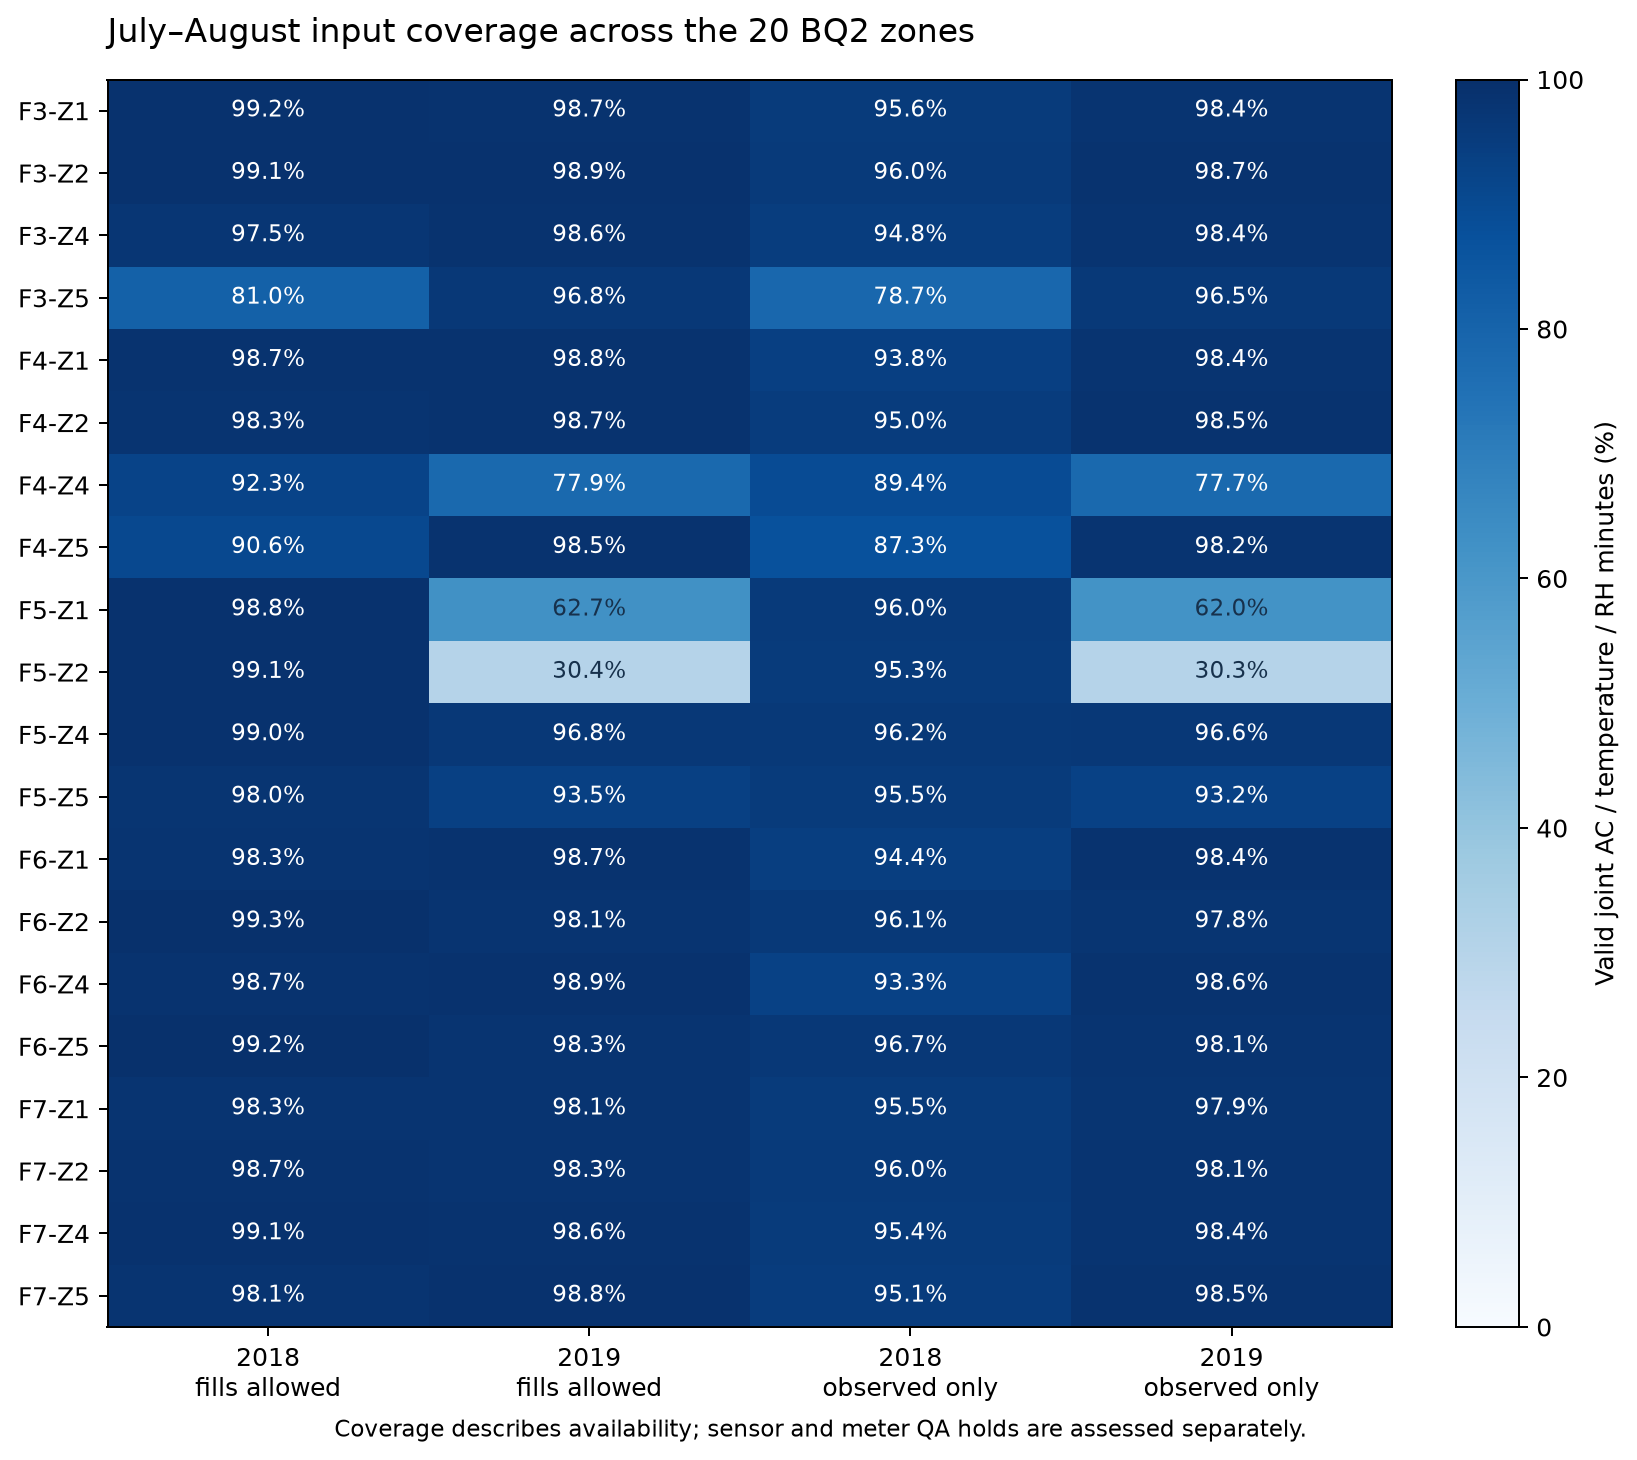

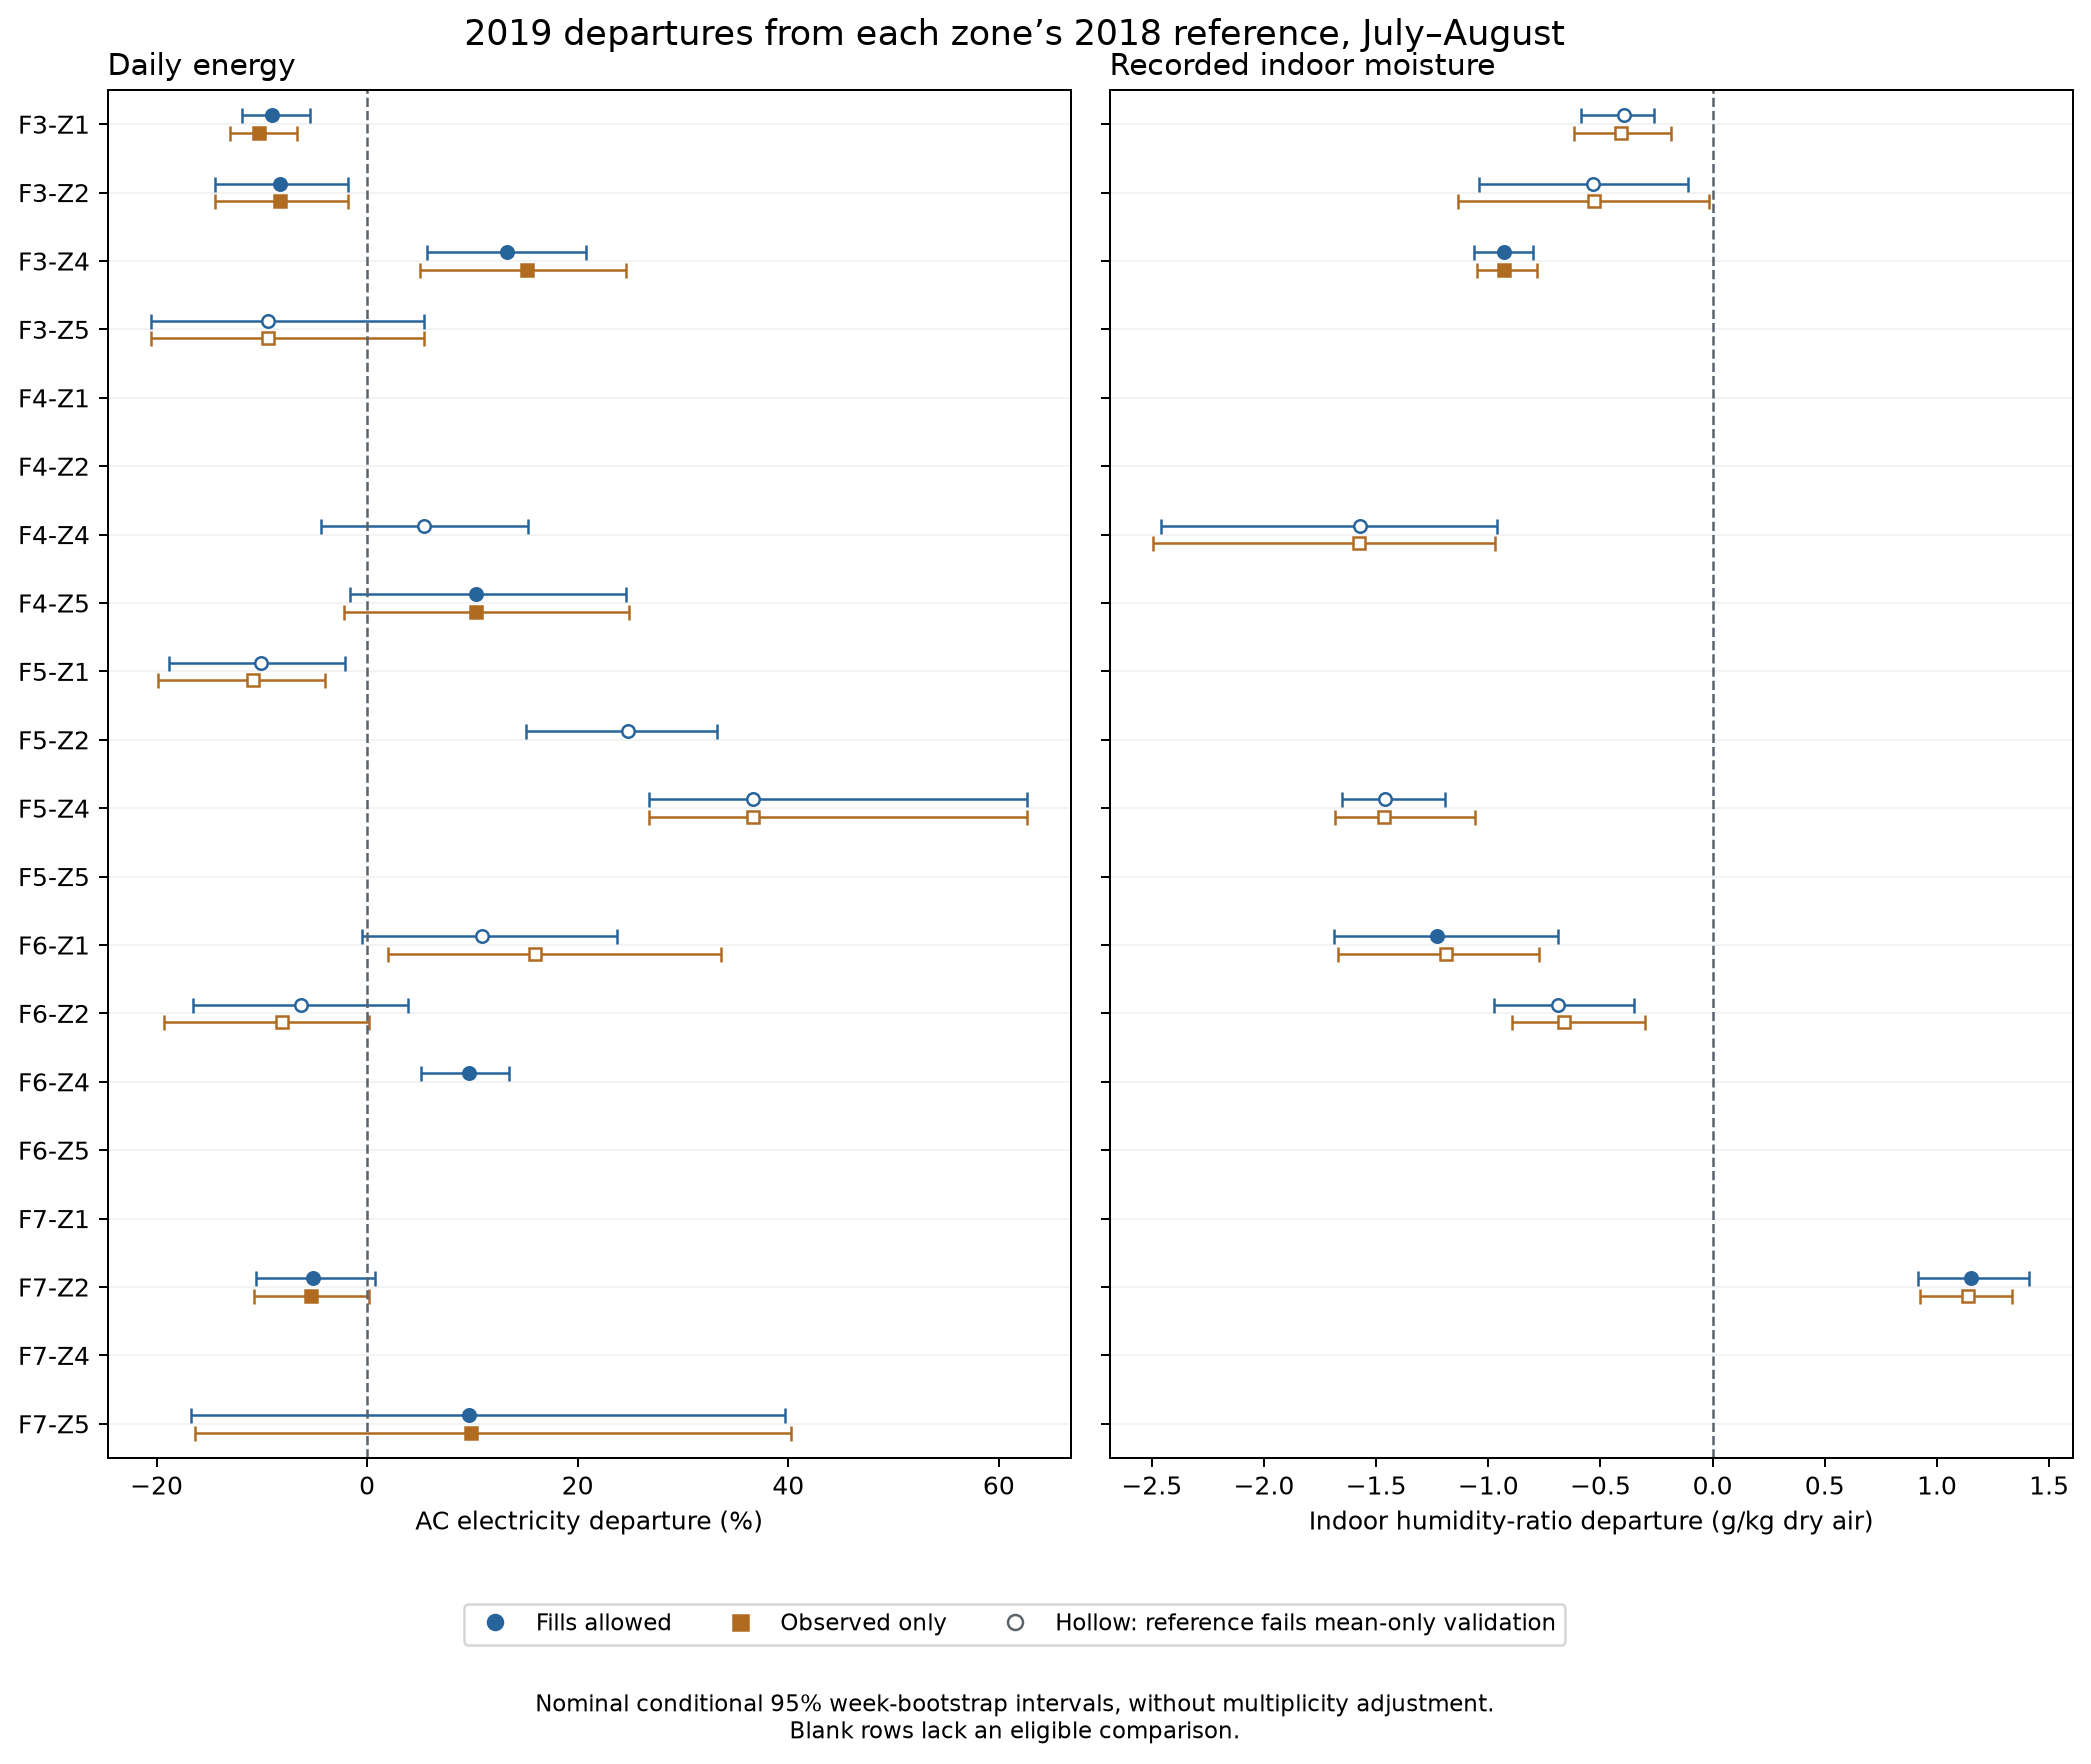

In [6]:
screen.plot_evidence(evidence, summary, output_dir)
display(Image(filename=str(output_dir / "input_coverage.png")))
display(Image(filename=str(output_dir / "zone_comparison.png")))


## 4. Filling sensitivity and missing comparisons

The complete-day rule is deliberately strict. A few missing or replaced minutes on every day can leave zero complete observed-only reference days despite high minute coverage. Such a result is **unavailable**, not zero energy or no risk. We retain this limitation rather than scaling partial days to 24 hours. Both input versions change sample membership as well as preprocessing.


**Provisional leads:** F5-Z2 shows +24.7% energy and F6-Z4 +9.7% with fills allowed, but neither has complete observed-only 2018 energy reference days under the strict rule. Retain them for data/reference follow-up rather than promoting them into the consistent two-version shortlist.


In [7]:
counts = result["cohort_counts"]
reference_energy = counts.query("analysis == 'energy' and variant == 'without_fills' and year == 2018")
display(reference_energy[reference_energy.days.lt(20)].merge(
    quality[["zone_id", "without_fills_2018_energy_coverage_pct"]], on="zone_id").round(3))
print("All metric/year/version counts are saved in cohort_counts.csv.")
# Describe the eligible cohorts without calling their unmatched means causal effects.
operating = evidence["daily_features"].query("eligible").groupby(["zone_id", "variant", "year"])[[
    "ac_kWh", "plug_kWh", "AC_on_hours", "on_mean_kW"]].mean().reset_index()
conditions = evidence["steady_on_features"].groupby(["zone_id", "variant", "year"])[[
    "temp_C", "rh_pct", "indoor_w_gkg", "humidity_gap_gkg"]].mean().reset_index()
operating.to_csv(output_dir / "operating_context.csv", index=False)
conditions.to_csv(output_dir / "recorded_conditions.csv", index=False)
display(operating[operating.zone_id.isin(focus)].round(3))
display(conditions[conditions.zone_id.isin(focus)].round(3))


,zone_id,analysis,variant,year,rows,days,without_fills_2018_energy_coverage_pct
0,F4-Z1,energy,without_fills,2018,0,0,98.972
1,F4-Z2,energy,without_fills,2018,0,0,99.358
2,F4-Z4,energy,without_fills,2018,0,0,99.226
3,F5-Z2,energy,without_fills,2018,0,0,98.937
4,F6-Z4,energy,without_fills,2018,0,0,98.338
5,F6-Z5,energy,without_fills,2018,0,0,98.879


All metric/year/version counts are saved in cohort_counts.csv.


,zone_id,variant,year,ac_kWh,plug_kWh,AC_on_hours,on_mean_kW
8,F3-Z4,with_fills,2018,132.221,7.270,6.753,19.312
9,F3-Z4,with_fills,2019,156.582,7.772,7.226,21.616
10,F3-Z4,without_fills,2018,132.221,7.270,6.753,19.312
11,F3-Z4,without_fills,2019,157.700,7.821,7.255,21.710
36,F5-Z4,with_fills,2018,112.762,23.058,7.448,15.132
37,F5-Z4,with_fills,2019,155.154,20.530,7.460,20.791
38,F5-Z4,without_fills,2018,112.762,23.058,7.448,15.132
39,F5-Z4,without_fills,2019,155.132,20.510,7.460,20.790
62,F7-Z2,with_fills,2018,217.800,2.355,8.467,25.727
63,F7-Z2,with_fills,2019,204.539,2.344,7.980,25.603


,zone_id,variant,year,temp_C,rh_pct,indoor_w_gkg,humidity_gap_gkg
8,F3-Z4,with_fills,2018,21.447,60.260,9.580,9.416
9,F3-Z4,with_fills,2019,17.908,67.159,8.564,10.419
10,F3-Z4,without_fills,2018,21.463,60.244,9.586,9.517
11,F3-Z4,without_fills,2019,17.902,67.163,8.561,10.415
40,F5-Z4,with_fills,2018,23.892,63.476,11.748,7.358
41,F5-Z4,with_fills,2019,19.860,71.643,10.344,8.747
42,F5-Z4,without_fills,2018,23.909,63.435,11.755,7.232
43,F5-Z4,without_fills,2019,19.863,71.635,10.346,8.733
64,F7-Z2,with_fills,2018,21.833,59.929,9.762,9.374
65,F7-Z2,with_fills,2019,21.495,68.612,10.967,8.072


## Review and handover

Prioritise **F3-Z4's energy/controls**, **F5-Z4's large energy change with a weak weather reference**, and **F7-Z2's recorded moisture increase with a validation caution**. Start with configuration/sensor checks in F4-Z1, F7-Z1 and F5-Z1. Review these evidence labels with the group rather than treating the table as a fault ranking.

The inspection shortlist is one row per `floor, zone`, includes every BQ2 zone and retains both versions' counts, intervals and limitations. It is separate from the planned `zone_ac_metrics.csv` contract and the joint risk matrix. No Track A notebook, upstream output or shared psychrometric definition is changed. No zone has a reportable adjusted cooling decline, and this narrow calendar comparison does not establish long-term deterioration, surface mould exposure or remaining life.

The figures and intervals are conditional exploratory summaries. Screening many correlated zones increases the chance of chance findings. Agreement across versions and benchmark sensitivity improves interpretability but does not provide independent replication, remove confounding or certify a fault.


In [8]:
# Final reproducibility and source-integrity checks.
assert len(quality) == 20 and not quality.duplicated(["floor", "zone"]).any()
assert len(summary) == 20 * 3 * 2
assert len(shortlist) == 20 and not shortlist.duplicated(["floor", "zone"]).any()
for table in [evidence["daily_features"], evidence["event_features"], evidence["steady_on_features"]]:
    assert table.time.dt.month.isin([7, 8]).all() and table.time.dt.year.isin([2018, 2019]).all()
for item in json.loads((output_dir / "input_manifest.json").read_text()):
    assert screen.digest(repo_root / item["path"]) == item["sha256"], item["path"]
assert summary.query("reportable").bootstrap_valid_replicates.ge(1800).all()
for analysis in ["energy", "moisture"]:
    old = pd.read_csv(Path("outputs/f3z1-first-pass/summary.csv")).query(
        "analysis == @analysis and evaluation == 'within_reference_support'").set_index("variant")
    new = summary.query("zone_id == 'F3-Z1' and analysis == @analysis").set_index("variant")
    np.testing.assert_allclose(new.loc[old.index, "mean_residual"], old.mean_residual, atol=1e-8)
report = {
    "scope": "20 BQ2 zones; July-August 2018 reference and July-August 2019 evaluation",
    "reference_gate": "20 days and four calendar weeks",
    "evaluation_gate": "10 supported days and four weeks; 2018 convex hull by session",
    "uncertainty": "2000 calendar-week bootstrap replicates; nominal conditional 95%; no multiplicity adjustment",
    "stronger_lead_gate": "consistent direction across both input versions; reference CV MAE <= mean-only CV MAE",
    "secondary_lead_gate": "consistent descriptive direction plus mean-only sensitivity; weak reference explicitly flagged",
    "versions": {p: metadata.version(p) for p in ["pandas", "numpy", "statsmodels", "scipy", "matplotlib"]},
    "code_sha256": {name: screen.digest(Path(name)) for name in ["bq2_zone_screen.py", "f3z1_first_pass.py", "f3z1_audit.py"]},
    "inspection_categories": shortlist.inspection_category.value_counts().to_dict(),
    "model_status_counts": summary.status.value_counts().to_dict(),
    "source_manifest": "input_manifest.json",
}
(output_dir / "summary.json").write_text(json.dumps(report, indent=2) + "\n")
print("All 20 zones retained; source hashes unchanged; F3-Z1 estimates reproduced; evidence saved.")


All 20 zones retained; source hashes unchanged; F3-Z1 estimates reproduced; evidence saved.
